# MET CS555: Homework 5

Chris Davis

## Questions

The data is from 3 groups of students (math, chemistry, and physics) on an IQ related test. The data is saved in data.csv and read into Python for the analysis below.

<em style="color:#333333">(1) How many students are in each group? Summarize the data relating to both test score and age by the student group (separately). Use appropriate numerical and/or graphical summaries. (3 points)</em>

There are 15 students in each group (N = 45).

Test score:

| Group | n | Mean | SD | Median | Min | Max |
|---|---:|---:|---:|---:|---:|---:|
| Chemistry | 15 | 46.27 | 3.73 | 46 | 40 | 52 |
| Math | 15 | 37.60 | 5.53 | 38 | 24 | 45 |
| Physics | 15 | 34.13 | 4.66 | 34 | 25 | 42 |

Age:

| Group | n | Mean | SD | Median | Min | Max |
|---|---:|---:|---:|---:|---:|---:|
| Chemistry | 15 | 40.07 | 4.22 | 41 | 32 | 46 |
| Math | 15 | 20.73 | 2.99 | 20 | 16 | 28 |
| Physics | 15 | 17.13 | 1.85 | 17 | 14 | 20 |

Chemistry has the highest scores. Those students are also about 20 years older than the math and physics students, so age is confounded with group. See appendix, question 1.

![Test score by group](iq_by_group.png)

![Age by group](age_by_group.png)


<em style="color:#333333">(2) Do the test scores vary by student group? Perform a one way ANOVA. Use a significance level of α = 0.05. Summarize the results using the 5-step procedure. If the results of the overall model are significant, perform the appropriate pairwise comparisons using Tukey’s procedure to adjust for multiple comparisons and summarize these results. (7 points)</em>

ANOVA table:

| Source | DF | SS | MS | F | p-value |
|---|---:|---:|---:|---:|---:|
| Group | 2 | 1171.73 | 585.87 | 26.57 | 3.50 × 10^-8 |
| Residual | 42 | 926.27 | 22.05 |  |  |
| Total | 44 | 2098.00 |  |  |  |

1. Null hypothesis: the mean test scores for chemistry, math, and physics are equal. Alternative: at least one mean differs. Alpha = 0.05.
2. One-way ANOVA F statistic. Numerator df = 2, denominator df = 42.
3. Reject H0 if F > 3.220; otherwise, fail to reject H0.
4. F = 26.57. The p-value is about 3.50 × 10^-8.
5. F is greater than 3.220, so reject H0. Mean test scores differ by student group.

Tukey comparisons (alpha = 0.05):

| Comparison | Mean difference | 95% CI | p-value |
|---|---:|---|---:|
| Math − Chemistry | -8.67 | (-12.83, -4.50) | < 0.001 |
| Physics − Chemistry | -12.13 | (-16.30, -7.97) | < 0.001 |
| Physics − Math | -3.47 | (-7.63, 0.70) | 0.120 |

Chemistry scores higher than math and higher than physics. Math and physics are not different from each other. See appendix, question 2.


<em style="color:#333333">(3) Create an appropriate number of dummy variables for student group and re-run the one-way ANOVA using the linear regression function with the newly created dummy variables. Set chemistry students as the reference group. Confirm the results are the same (specifically point out test statistics, p-values, etc. that show the results are equivalent). What is the interpretation of the beta estimates from the regression model? (4 points)</em>

Two dummy variables, with chemistry as the reference group:

Predicted score = 46.267 - 8.667 × Math - 12.133 × Physics.

The global F is 26.57 on (2, 42) degrees of freedom, p = 3.50 × 10^-8. The residual mean square is 22.05, and the group sum of squares is 1171.73. That matches the one-way ANOVA.

The intercept, 46.27, is the mean test score for chemistry students. Math students average 8.67 points lower than chemistry (t = -5.05, p < 0.001). Physics students average 12.13 points lower than chemistry (t = -7.08, p < 0.001). See appendix, question 3.


<em style="color:#333333">(4) Re-do the one-way ANOVA adjusting for age (ANCOVA). Focus on the output relating to the comparisons of test score by student type. Explain how this analysis differs from the analysis in step 2 above (not the results but how does this analysis differ in terms of the questions it answers as opposed to the one above). Did you obtain different results? Summarize briefly (no need to go through the 5-step procedure here). Lastly, present the least square means and interpret these. (2 points)</em>

Question 2 asks whether the groups differ in mean test score, ignoring age. The ANCOVA asks whether they differ after holding age constant.

After adjusting for age, group is not significant (F = 0.56, df = (2, 41), p = 0.575). Relative to chemistry, the math coefficient is 1.92 (t = 0.43, p = 0.669) and the physics coefficient is 0.42 (t = 0.08, p = 0.935). Age is associated with score: 0.548 points per year (t = 2.55, p = 0.015).

The result is different from question 2. The unadjusted means differ, but the group differences drop out once age is accounted for. Chemistry students are much older, which lines up with their higher unadjusted scores.

Least squares means at the average age (25.98 years):

| Group | Least squares mean |
|---|---:|
| Chemistry | 38.55 |
| Math | 40.47 |
| Physics | 38.98 |

If the groups were the same age, the estimated mean scores would be close. See appendix, question 4.


<em style="color:#333333">(5) Consider the following multiple regression model, with n = 25:</em>

<em style="color:#333333">y = 5 + 10x1 + 20x2</em>

<em style="color:#333333">The value of R² = 0.90, residual sum of squares associated to two parameters are as follows: Sx1 = 3.2, sx2 = 5.5.</em>

<em style="color:#333333">Calculate the F-test statistic associated to the global F-test. (2 points)</em>

F = (R² / k) / ((1 − R²) / (n − k − 1)), with R² = 0.90, k = 2, and n = 25.

F = (0.90 / 2) / (0.10 / 22) = 99.

The degrees of freedom are (2, 22). Sx1 and sx2 are not used for the global F. See appendix, question 5.


## Appendix: Code

In [ ]:
# Setup

%pip install numpy pandas matplotlib scipy statsmodels


In [2]:
# Setup

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy import stats

%matplotlib inline


In [3]:
# Read the data

students = pd.read_csv("data.csv")
students["group"] = pd.Categorical(
    students["group"], categories=["Chemistry", "Math", "Physics"]
)
print("rows read =", len(students))
print(students.head())


rows read = 45
     group  iq  age
0  Physics  34   15
1  Physics  33   17
2  Physics  32   15
3  Physics  25   14
4  Physics  36   19


             iq                               age                            
          count   mean   std median min max count   mean   std median min max
group                                                                        
Chemistry    15  46.27  3.73   46.0  40  52    15  40.07  4.22   41.0  32  46
Math         15  37.60  5.53   38.0  24  45    15  20.73  2.99   20.0  16  28
Physics      15  34.13  4.66   34.0  25  42    15  17.13  1.85   17.0  14  20


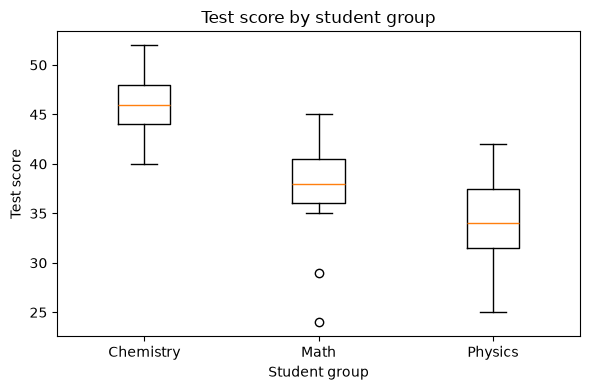

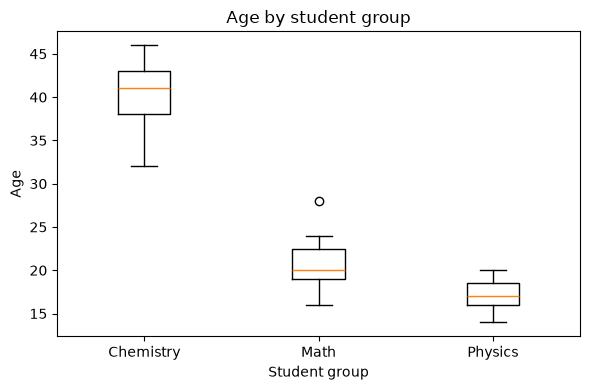

In [4]:
# Question 1

summary = (
    students.groupby("group", observed=True)[["iq", "age"]]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .round(2)
)
print(summary)

order = ["Chemistry", "Math", "Physics"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(
    [students.loc[students.group == g, "iq"] for g in order],
    tick_labels=order,
)
ax.set_xlabel("Student group")
ax.set_ylabel("Test score")
ax.set_title("Test score by student group")
plt.tight_layout()
plt.savefig("iq_by_group.png")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(
    [students.loc[students.group == g, "age"] for g in order],
    tick_labels=order,
)
ax.set_xlabel("Student group")
ax.set_ylabel("Age")
ax.set_title("Age by student group")
plt.tight_layout()
plt.savefig("age_by_group.png")
plt.show()


In [5]:
# Question 2

anova_model = smf.ols("iq ~ C(group)", data=students).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=1)
print(anova_table)

f_crit = stats.f.ppf(0.95, 2, 42)
print("F critical value =", round(f_crit, 3))

tukey = pairwise_tukeyhsd(students["iq"], students["group"], alpha=0.05)
print(tukey)


            df       sum_sq     mean_sq          F        PR(>F)
C(group)   2.0  1171.733333  585.866667  26.565136  3.495760e-08
Residual  42.0   926.266667   22.053968        NaN           NaN
F critical value = 3.22


   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1   group2 meandiff p-adj   lower    upper  reject
---------------------------------------------------------
Chemistry    Math  -8.6667    0.0 -12.8328 -4.5006   True
Chemistry Physics -12.1333    0.0 -16.2994 -7.9672   True
     Math Physics  -3.4667 0.1195  -7.6328  0.6994  False
---------------------------------------------------------


In [6]:
# Question 3

# Same model as question 2. C(group) makes the dummies, chemistry first.
print(anova_model.summary())


                            OLS Regression Results                            
Dep. Variable:                     iq   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.537
Method:                 Least Squares   F-statistic:                     26.57
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           3.50e-08
Time:                        22:06:40   Log-Likelihood:                -131.90
No. Observations:                  45   AIC:                             269.8
Df Residuals:                      42   BIC:                             275.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              46.2667    

In [7]:
# Question 4

ancova = smf.ols("iq ~ C(group) + age", data=students).fit()
print(ancova.summary())
print(sm.stats.anova_lm(ancova, typ=2))

mean_age = students["age"].mean()
print("mean age =", round(mean_age, 2))
grid = pd.DataFrame({"group": order, "age": mean_age})
predicted = ancova.predict(grid)
for group, value in zip(order, predicted):
    print(group, round(value, 2))


                            OLS Regression Results                            
Dep. Variable:                     iq   R-squared:                       0.619
Model:                            OLS   Adj. R-squared:                  0.591
Method:                 Least Squares   F-statistic:                     22.18
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.08e-08
Time:                        22:06:40   Log-Likelihood:                -128.60
No. Observations:                  45   AIC:                             265.2
Df Residuals:                      41   BIC:                             272.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              24.3263    

In [8]:
# Question 5

r_squared = 0.90
n = 25
k = 2
f_stat = (r_squared / k) / ((1 - r_squared) / (n - k - 1))
print("F =", round(f_stat, 2))
print("df =", (k, n - k - 1))


F = 99.0
df = (2, 22)
